# KSG Estimator — Computational Scaling Analysis

This notebook measures the computational cost of the KSG mutual information 
estimator as a function of dataset size.

## Motivation
The KSG estimator requires computing pairwise distances between all points,
which becomes expensive as N grows. Before we can develop faster methods,
we need to document exactly how the runtime scales with sample size.

## Experimental Design
- Dataset type: independent uniform random variables (2 variables, X and Y)
- Sample sizes: N = 250, 500, 750, ..., 3000 (steps of 250)
- Trials per size: 10 independent runs
- Metric recorded: wall clock time per estimation in seconds

In [53]:
import sys
import numpy as np
import time
import pandas as pd
import matplotlib.pyplot as plt
import dataframe_image as dfi
from IPython.display import HTML
import gc

sys.path.append('..')

from python.ksg_estimator import mi_knn

%matplotlib inline
print("Imports successful")

Imports successful


In [61]:
# Experimental Design
# Sample sizes from 250 to 3000 in steps of 250
sample_sizes = list(range(250, 3001, 250))

# Number of independent trials per sample size
n_trials = 10

# K value for KSG estimator
K = 2

# Store raw timing results
results = []

print("Running scaling analysis...")
print(f"Sample sizes: {sample_sizes}")
print(f"Trials per size: {n_trials}\n")

# Run the experiment
for n in sample_sizes:
    trial_times = []
    
    for trial in range(n_trials):
        # Generate a fresh independent uniform random dataset for each trial
        # Using a different seed for each trial makes the datasets reproducible
        rng = np.random.default_rng(trial)
        x = rng.uniform(0, 1, size=(n, 1))
        y = rng.uniform(0, 1, size=(n, 1))
        
        # Record start time
        start = time.perf_counter()
        
        # Run the KSG estimator
        mi_knn(x, y, K=K)
        
        # Record end time
        elapsed = time.perf_counter() - start
        
        # Store the raw runtime for this trial
        trial_times.append(elapsed)
    
    # Store all trial times for this sample size
    for trial_idx, t in enumerate(trial_times):
        results.append({
            'N': n,
            'Trial': trial_idx + 1,
            'Time (s)': t
        })
    
    print(f"N={n:>5} | mean={np.mean(trial_times):.4f}s | "
          f"median={np.median(trial_times):.4f}s | "
          f"min={min(trial_times):.4f}s | "
          f"max={max(trial_times):.4f}s")

# Build results table
# Reshape into wide format: rows = sample sizes, columns = trials
table_data = {}

for n in sample_sizes:
    n_rows = [r for r in results if r['N'] == n]
    table_data[n] = [r['Time (s)'] for r in n_rows]

# Convert to DataFrame
df = pd.DataFrame(table_data).T
df.columns = [f'Trial {i+1}' for i in range(n_trials)]
df.index.name = 'N'

# Store trial column names separately
# This prevents summary columns from being included in later calculations
trial_cols = [f'Trial {i+1}' for i in range(n_trials)]

# Add summary columns using only the trial columns
df['Mean (s)'] = df[trial_cols].mean(axis=1)
df['Median (s)'] = df[trial_cols].median(axis=1)
df['Min (s)'] = df[trial_cols].min(axis=1)
df['Max (s)'] = df[trial_cols].max(axis=1)
df['Std (s)'] = df[trial_cols].std(axis=1)

# Round only for display
df_display = df.round(6)

# Display results
print("\nKSG Estimator Runtime Scaling Analysis")
print("=" * 120)
print(df_display.to_string())

Running scaling analysis...
Sample sizes: [250, 500, 750, 1000, 1250, 1500, 1750, 2000, 2250, 2500, 2750, 3000]
Trials per size: 10

N=  250 | mean=0.0019s | median=0.0017s | min=0.0013s | max=0.0034s
N=  500 | mean=0.0052s | median=0.0052s | min=0.0047s | max=0.0060s
N=  750 | mean=0.0119s | median=0.0117s | min=0.0115s | max=0.0138s
N= 1000 | mean=0.0223s | median=0.0216s | min=0.0213s | max=0.0280s
N= 1250 | mean=0.0362s | median=0.0349s | min=0.0336s | max=0.0492s
N= 1500 | mean=0.0530s | median=0.0524s | min=0.0502s | max=0.0598s
N= 1750 | mean=0.0729s | median=0.0713s | min=0.0708s | max=0.0866s
N= 2000 | mean=0.0998s | median=0.0923s | min=0.0898s | max=0.1687s
N= 2250 | mean=0.1223s | median=0.1183s | min=0.1151s | max=0.1614s
N= 2500 | mean=0.1585s | median=0.1487s | min=0.1431s | max=0.1965s
N= 2750 | mean=0.1843s | median=0.1787s | min=0.1740s | max=0.2256s
N= 3000 | mean=0.2445s | median=0.2194s | min=0.2084s | max=0.4138s

KSG Estimator Runtime Scaling Analysis
       Tria

## Results Table

Each row is a sample size N. Each column shows the runtime in seconds
for one of the 10 independent trials, followed by summary statistics.

In [62]:
# Build the dataframe fresh from current results
table_data = {}
for n in sample_sizes:
    n_rows = [r for r in results if r['N'] == n]
    table_data[n] = [r['Time (s)'] for r in n_rows]

df = pd.DataFrame(table_data).T
df.columns = [f'Trial {i+1}' for i in range(n_trials)]

# Add summary columns
df['Mean (s)'] = df.mean(axis=1).round(6)
df['Median (s)'] = df.median(axis=1).round(6)
df['Min (s)']  = df.min(axis=1).round(6)
df['Max (s)']  = df.max(axis=1).round(6)
df['Std (s)']  = df.std(axis=1).round(6)

# Column groups
summary_cols = ['Mean (s)', 'Median (s)', 'Min (s)', 'Max (s)', 'Std (s)']
trial_cols   = [f'Trial {i+1}' for i in range(n_trials)]
all_cols     = trial_cols + summary_cols

# Build pure HTML table - no pandas styling
css = """
<style>
    .ksg-table {
        border-collapse: collapse;
        font-family: monospace;
        font-size: 11px;
        width: 100%;
    }
    .ksg-table caption {
        font-size: 13px;
        font-weight: bold;
        color: #2c3e50;
        text-align: left;
        margin-bottom: 8px;
        font-family: Arial, sans-serif;
    }
    .ksg-table th {
        background-color: #2c3e50;
        color: white;
        padding: 8px 10px;
        text-align: center;
        border: 1px solid #ccc;
    }
    .ksg-table th.corner {
        background-color: #1a252f;
        font-style: italic;
        font-size: 11px;
        text-align: center;
    }
    .ksg-table td {
        padding: 6px 10px;
        text-align: center;
        border: 1px solid #ddd;
    }
    .ksg-table td.summary {
        background-color: #eaf0fb;
        font-weight: bold;
    }
    .ksg-table tr:nth-child(even) td {
        background-color: #f9f9f9;
    }
    .ksg-table tr:nth-child(even) td.summary {
        background-color: #ddeaf7;
    }
    .ksg-table tr:hover td {
        background-color: #f0f4f8;
    }
</style>
"""

# Single header row with N/Trial in the corner
header = '<tr>'
header += '<th class="corner">N / Trial</th>'
for col in all_cols:
    header += f'<th>{col}</th>'
header += '</tr>'

# Data rows
rows = ''
for n in sample_sizes:
    rows += '<tr>'
    rows += f'<th>{n}</th>'
    for col in all_cols:
        val = df.loc[n, col]
        cls = 'summary' if col in summary_cols else ''
        rows += f'<td class="{cls}">{val:.6f}</td>'
    rows += '</tr>'

# Assemble
html_table = f"""
{css}
<table class="ksg-table">
    <caption>KSG Estimator Runtime Scaling Analysis - N=250 to N=3,000 (10 trials each, times in seconds)</caption>
    <thead>{header}</thead>
    <tbody>{rows}</tbody>
</table>
"""

# Save to file
output_path = '../notebooks/runtime_table.html'
with open(output_path, 'w') as f:
    f.write(html_table)
print(f"Table saved to: {output_path}")

# Display inline in notebook
HTML(html_table)

Table saved to: ../notebooks/runtime_table.html


N / Trial,Trial 1,Trial 2,Trial 3,Trial 4,Trial 5,Trial 6,Trial 7,Trial 8,Trial 9,Trial 10,Mean (s),Median (s),Min (s),Max (s),Std (s)
250,0.003412,0.003052,0.001951,0.001380,0.001330,0.001646,0.001380,0.001506,0.001830,0.001733,0.001922,0.001733,0.001330,0.003412,0.000749
500,0.006039,0.005669,0.005543,0.004918,0.004840,0.005521,0.004691,0.004762,0.005527,0.004744,0.005225,0.005225,0.004691,0.006039,0.000485
750,0.013787,0.012451,0.011707,0.011907,0.011638,0.011508,0.011508,0.011635,0.011503,0.011671,0.011932,0.011671,0.011503,0.013787,0.000792
1000,0.027963,0.022361,0.021493,0.022371,0.021425,0.021400,0.022080,0.021704,0.021284,0.021257,0.022334,0.021704,0.021257,0.027963,0.002303
1250,0.049164,0.034700,0.033776,0.033642,0.034163,0.034101,0.035121,0.036247,0.035260,0.035416,0.036159,0.035121,0.033642,0.049164,0.005292
1500,0.059772,0.052340,0.050222,0.054358,0.053017,0.052476,0.052100,0.052418,0.052123,0.051654,0.053048,0.052418,0.050222,0.059772,0.002944
1750,0.086631,0.072386,0.071587,0.071021,0.071461,0.071085,0.070855,0.070797,0.070861,0.072707,0.072939,0.071461,0.070797,0.086631,0.005542
2000,0.168704,0.091684,0.089888,0.089773,0.089850,0.092997,0.095452,0.094257,0.090200,0.094957,0.099776,0.092997,0.089773,0.168704,0.027771
2250,0.161355,0.119513,0.118601,0.119463,0.122821,0.118047,0.115727,0.115114,0.115191,0.116784,0.122262,0.118601,0.115114,0.161355,0.015895
2500,0.196510,0.164372,0.151646,0.146383,0.148942,0.148408,0.146844,0.194091,0.144469,0.143147,0.158481,0.148942,0.143147,0.196510,0.020496


## Findings

To evaluate the computational cost of the current Python implementation of the KSG mutual information estimator, we measured the runtime for sample sizes ranging from \(N=250\) to \(N=3000\). For each sample size, we generated 10 independent random datasets consisting of two uniformly distributed variables and recorded the wall-clock execution time required to compute the mutual information estimate.

The main findings from this experiment are:

- **Runtime increases consistently with sample size**
  
  The mean runtime increased from approximately **0.002 seconds** at \(N=250\) to approximately **0.223 seconds** at \(N=3000\), demonstrating a clear growth in computational cost as the number of samples increases.

- **The growth is clearly nonlinear**
  
  The increase in runtime is substantially faster than what would be expected from a linear scaling relationship. As \(N\) grows, the computational cost increases at an accelerating rate.

- **Dataset randomness has minimal impact on runtime**
  
  Each timing measurement was performed using a newly generated random dataset. Despite this, the runtimes remained relatively consistent across trials, indicating that execution time is driven primarily by sample size rather than the particular realization of the data. This is expected for KNN-based methods, where the dominant cost is tree construction and neighbor search: operations that scale with (N) regardless of the specific data values.

- **Runtime variability remains relatively small**
  
  Although the standard deviation increases slightly for larger sample sizes, the overall trend remains stable and reproducible across independent trials.

- **The first trial at many sample sizes is consistently slower than the subsequent trials**

  This behavior is reflected by the systematic difference between the mean and median runtime at several sample sizes. In many cases, the largest runtime corresponds to Trial 1, while the remaining trials are clustered much more tightly together. This suggests the presence of initialization, memory allocation, cache-warming, or other one-time overheads that are not directly related to the computational cost of the KSG estimator itself.

  Because the median is less sensitive to these outliers, it provides a useful measure of the typical runtime for a given sample size.

Overall, the results indicate that the computational cost of the current KSG implementation increases rapidly with sample size and becomes increasingly expensive even within the relatively modest range of sample sizes considered in this experiment.

---

## Constraints

The following limitations should be considered when interpreting these results:

- **Limited sample size range**
  
  This experiment only considered sample sizes between \(N=250\) and \(N=3000\). While sufficient to observe the overall growth trend, this range may not fully capture the asymptotic behavior of the implementation at larger scales.

- **Fixed neighbor count**

  All measurements were performed with (K=2). Different values of (K) would shift the absolute runtimes, as the number of neighbors queried directly affects the cost of each KNN lookup.

- **Wall-clock timing measurements**
  
  The recorded runtimes include effects beyond the algorithm itself, such as memory allocation, cache behavior, operating system scheduling, and background system activity.

- **Specific data distribution**
  
  All datasets were generated using independent uniformly distributed random variables. Although runtime is expected to depend primarily on \(N\), different data structures, dimensionalities, or distributions may influence performance characteristics.

- **Empirical scaling only**
  
  This experiment was designed to characterize observed runtime growth. While the results provide evidence regarding computational scaling, they do not by themselves establish the formal asymptotic time complexity of the implementation.

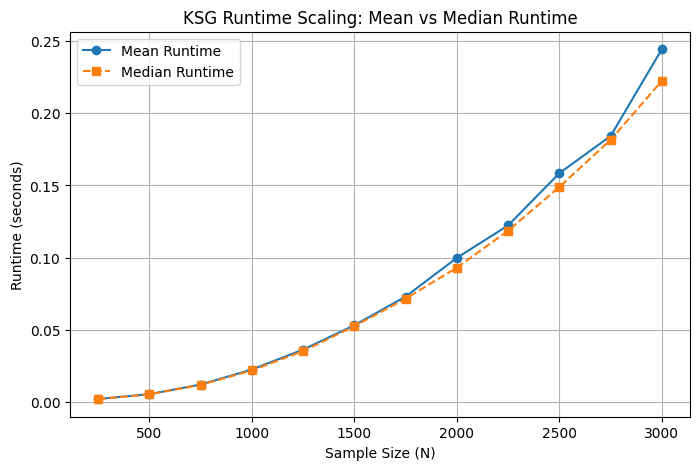

In [63]:
#Mean and Median vs Number of samples run time plot
plt.figure(figsize=(8, 5))

plt.plot(
    df.index,
    df['Mean (s)'],
    marker='o',
    label='Mean Runtime'
)

plt.plot(
    df.index,
    df['Median (s)'],
    marker='s',
    linestyle='--',
    label='Median Runtime'
)

plt.xlabel('Sample Size (N)')
plt.ylabel('Runtime (seconds)')
plt.title('KSG Runtime Scaling: Mean vs Median Runtime')
plt.grid(True)
plt.legend()

plt.show()

## Mean vs Median Runtime Analysis
To better understand the effect of slower trials on the runtime measurements, we compared the mean and median runtime for each sample size. Both curves increase consistently with (N), confirming that the growth in computational cost is a genuine scaling effect rather than an artifact of isolated outliers. The mean runtime is slightly higher than the median at several sample sizes, consistent with the influence of occasional slower trials noted above.
Because the median is less sensitive to timing spikes caused by initialization, memory allocation, cache effects, or background system activity, it provides a more stable estimate of the typical runtime at each sample size. For this reason, we report both measures throughout the analysis: the mean captures the average behavior across all trials, while the median reflects the more typical runtime at each sample size.

In [64]:
#Use median runtime because it is less sensitive to first-trial overhead
x = np.log(df.index)
y = np.log(df['Median (s)'])

slope, intercept = np.polyfit(x, y, 1)

print(f"Estimated empirical scaling exponent using median runtime: p = {slope:.3f}")

Estimated empirical scaling exponent using median runtime: p = 1.999


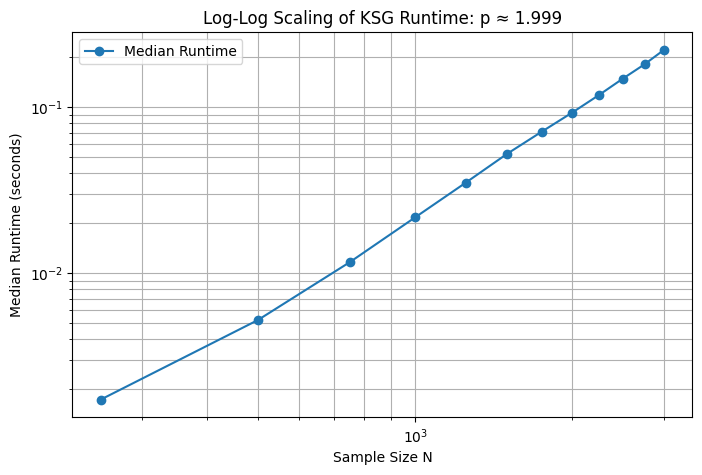

In [65]:
plt.figure(figsize=(8, 5))

plt.loglog(
    df.index,
    df['Median (s)'],
    marker='o',
    label='Median Runtime'
)

plt.xlabel('Sample Size N')
plt.ylabel('Median Runtime (seconds)')
plt.title(f'Log-Log Scaling of KSG Runtime: p ≈ {slope:.3f}')
plt.grid(True, which='both')
plt.legend()

plt.show()

In [66]:
# Remove very small N values where timing overhead dominates
df_large = df[df.index >= 1000]

x_large = np.log(df_large.index)
y_large = np.log(df_large['Median (s)'])

slope_large, intercept_large = np.polyfit(x_large, y_large, 1)

print(f"Estimated empirical scaling exponent for N >= 1000: p = {slope_large:.3f}")

Estimated empirical scaling exponent for N >= 1000: p = 2.096


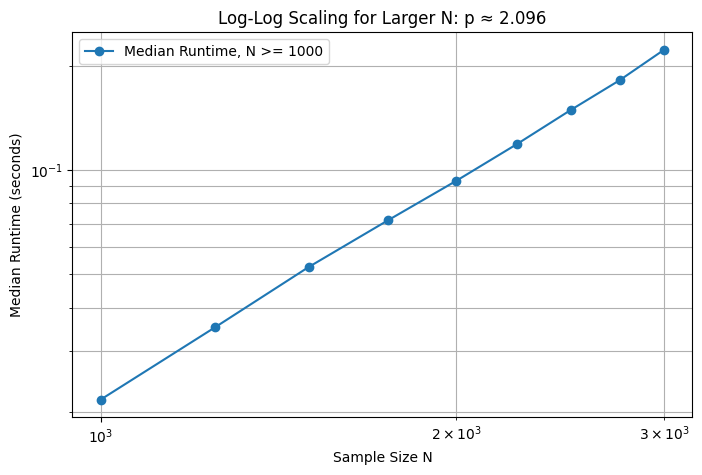

In [67]:
plt.figure(figsize=(8, 5))

plt.loglog(
    df_large.index,
    df_large['Median (s)'],
    marker='o',
    label='Median Runtime, N >= 1000'
)

plt.xlabel('Sample Size N')
plt.ylabel('Median Runtime (seconds)')
plt.title(f'Log-Log Scaling for Larger N: p ≈ {slope_large:.3f}')
plt.grid(True, which='both')
plt.legend()

plt.show()

## Empirical Scaling from Median Runtime

Because the first trial is often slower than the remaining trials for many sample sizes, I used the median runtime to estimate the empirical scaling behavior. The median is less sensitive to first-trial overhead and other occasional timing spikes, so it gives a better representation of the typical runtime for each sample size.

Using all sample sizes from \(N=250\) to \(N=3000\), the log-log fit produced an empirical scaling exponent of approximately:

\[
p $\approx$ 1.999
\]

When restricting the fit to larger sample sizes, \(N $\geq$ 1000\), the estimated exponent was:

\[
p $\approx$ 2.096
\]

Both estimates are very close to 2, suggesting that the observed runtime grows approximately quadratically over the tested range. The relative ordering of the two exponents varies slightly across repeated runs, reflecting the sensitivity of log-log fits to small fluctuations in wall-clock timing at any given sample size. Neither estimate should be treated as more authoritative than the other, together they indicate that the scaling behavior is consistently close to quadratic regardless of whether small sample sizes are included in the fit.

The exact runtime values may change slightly between repeated executions because wall-clock timing depends on factors such as memory allocation, cache behavior, operating system scheduling, and background system activity. However, the overall scaling trend remained stable and close to quadratic.

In [68]:
# Extended Experimental Design
# Sample sizes beyond the original N = 250 to N = 3000 experiment
extended_sample_sizes = [3000, 4000, 5000, 7500, 10000]

# Number of independent trials per sample size
# Keeping 10 trials to match the original experiment
n_trials_extended = 10

# K value for KSG estimator
K = 2

# Store raw timing results
extended_results = []

print("Running extended scaling analysis...")
print(f"Sample sizes: {extended_sample_sizes}")
print(f"Trials per size: {n_trials_extended}\n")

# Run the extended experiment
for n in extended_sample_sizes:
    trial_times = []
    
    for trial in range(n_trials_extended):
        # Generate a fresh independent uniform random dataset for each trial
        # Using a different seed for each trial makes the datasets reproducible
        rng = np.random.default_rng(trial)
        x = rng.uniform(0, 1, size=(n, 1))
        y = rng.uniform(0, 1, size=(n, 1))
        
        # Record start time
        start = time.perf_counter()
        
        # Run the KSG estimator
        mi_knn(x, y, K=K)
        
        # Record end time
        elapsed = time.perf_counter() - start
        
        # Store the raw runtime for this trial
        trial_times.append(elapsed)
        
        # Delete x and y before the next trial to reduce memory pressure
        del x, y
        gc.collect()
    
    # Store all trial times for this sample size
    for trial_idx, t in enumerate(trial_times):
        extended_results.append({
            'N': n,
            'Trial': trial_idx + 1,
            'Time (s)': t
        })
    
    print(f"N={n:>6} | mean={np.mean(trial_times):.4f}s | "
          f"median={np.median(trial_times):.4f}s | "
          f"min={min(trial_times):.4f}s | "
          f"max={max(trial_times):.4f}s")

# Build extended results table
# Reshape into wide format: rows = sample sizes, columns = trials
extended_table_data = {}

for n in extended_sample_sizes:
    n_rows = [r for r in extended_results if r['N'] == n]
    extended_table_data[n] = [r['Time (s)'] for r in n_rows]

# Convert to DataFrame
extended_df = pd.DataFrame(extended_table_data).T
extended_df.columns = [f'Trial {i+1}' for i in range(n_trials_extended)]
extended_df.index.name = 'N'

# Store trial column names separately
# This prevents summary columns from being included in later calculations
extended_trial_cols = [f'Trial {i+1}' for i in range(n_trials_extended)]

# Add summary columns using only the trial columns
extended_df['Mean (s)'] = extended_df[extended_trial_cols].mean(axis=1)
extended_df['Median (s)'] = extended_df[extended_trial_cols].median(axis=1)
extended_df['Min (s)'] = extended_df[extended_trial_cols].min(axis=1)
extended_df['Max (s)'] = extended_df[extended_trial_cols].max(axis=1)
extended_df['Std (s)'] = extended_df[extended_trial_cols].std(axis=1)

# Round only for display
extended_df_display = extended_df.round(6)

# Display results
print("\nExtended KSG Estimator Runtime Scaling Analysis")
print("=" * 120)
print(extended_df_display.to_string())

Running extended scaling analysis...
Sample sizes: [3000, 4000, 5000, 7500, 10000]
Trials per size: 10

N=  3000 | mean=0.2166s | median=0.2067s | min=0.2060s | max=0.2982s
N=  4000 | mean=0.4430s | median=0.4200s | min=0.3779s | max=0.7180s
N=  5000 | mean=0.6726s | median=0.6243s | min=0.5982s | max=1.0684s
N=  7500 | mean=1.6451s | median=1.4816s | min=1.4152s | max=2.6181s
N= 10000 | mean=3.2349s | median=3.0259s | min=2.5746s | max=4.7947s

Extended KSG Estimator Runtime Scaling Analysis
        Trial 1   Trial 2   Trial 3   Trial 4   Trial 5   Trial 6   Trial 7   Trial 8   Trial 9  Trial 10  Mean (s)  Median (s)   Min (s)   Max (s)   Std (s)
N                                                                                                                                                            
3000   0.298159  0.211337  0.209314  0.208566  0.206717  0.206291  0.206049  0.206317  0.206747  0.206062  0.216556    0.206732  0.206049  0.298159  0.028725
4000   0.718008  0.448850  0

Empirical Scaling Exponent Summary
Extended only  (N = 3000 to 10000) : p = 2.184
Combined full  (N =  250 to 10000) : p = 2.051
Combined large (N >= 1000)         : p = 2.117
Original experiment (for reference):
Full range     (N =  250 to  3000) : p = 1.999
Large N only   (N >= 1000)         : p = 2.096


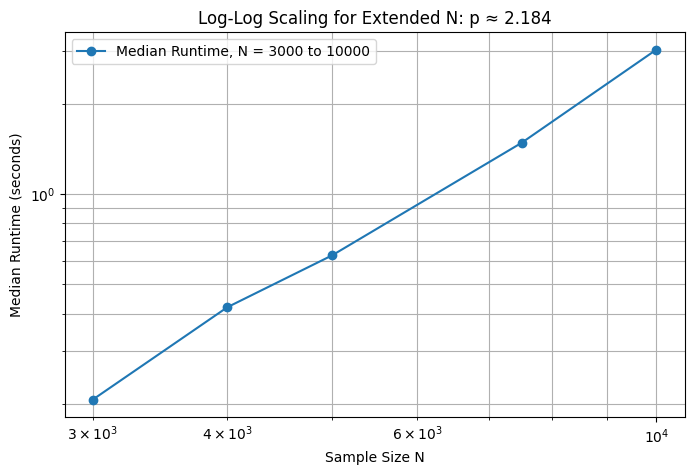

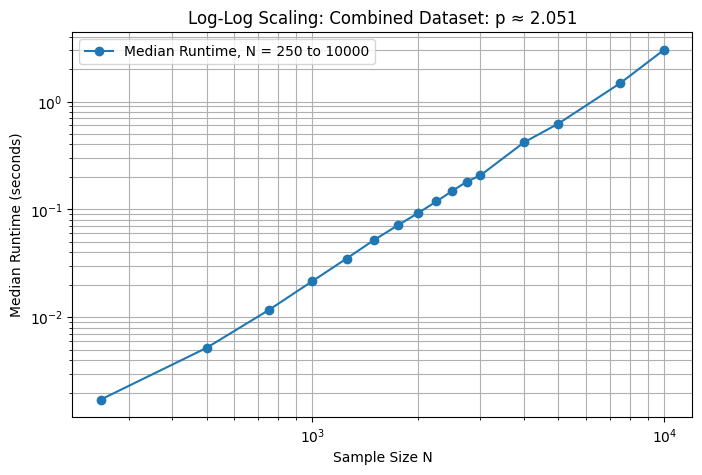

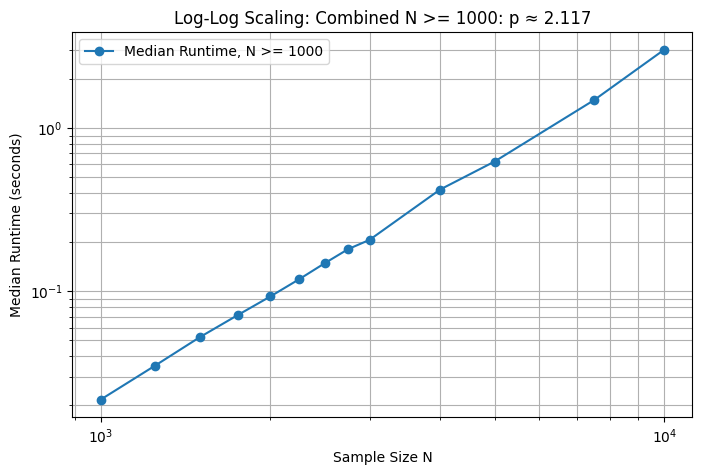

In [ ]:
# Summary of Empirical Scaling Exponents
print("Empirical Scaling Exponent Summary")
print("=" * 45)
print(f"Extended only  (N = 3000 to 10000) : p = {slope_extended:.3f}")
print(f"Combined full  (N =  250 to 10000) : p = {slope_combined:.3f}")
print(f"Combined large (N >= 1000)         : p = {slope_combined_large:.3f}")
print("=" * 45)
print("Original experiment (for reference):")
print(f"Full range     (N =  250 to  3000) : p = {slope:.3f}")
print(f"Large N only   (N >= 1000)         : p = {slope_large:.3f}")

# Plot 1: Extended dataset only (N = 3000 to 10000)
plt.figure(figsize=(8, 5))

plt.loglog(
    extended_df.index,
    extended_df['Median (s)'],
    marker='o',
    label='Median Runtime, N = 3000 to 10000'
)

plt.xlabel('Sample Size N')
plt.ylabel('Median Runtime (seconds)')
plt.title(f'Log-Log Scaling for Extended N: p ≈ {slope_extended:.3f}')
plt.grid(True, which='both')
plt.legend()

plt.show()

# Plot 2: Combined dataset (N = 250 to 10000)
plt.figure(figsize=(8, 5))

plt.loglog(
    df_combined.index,
    df_combined['Median (s)'],
    marker='o',
    label='Median Runtime, N = 250 to 10000'
)

plt.xlabel('Sample Size N')
plt.ylabel('Median Runtime (seconds)')
plt.title(f'Log-Log Scaling: Combined Dataset: p ≈ {slope_combined:.3f}')
plt.grid(True, which='both')
plt.legend()

plt.show()

# Plot 3: Combined dataset, large N only (N >= 1000)
plt.figure(figsize=(8, 5))

plt.loglog(
    df_combined_large.index,
    df_combined_large['Median (s)'],
    marker='o',
    label='Median Runtime, N >= 1000'
)

plt.xlabel('Sample Size N')
plt.ylabel('Median Runtime (seconds)')
plt.title(f'Log-Log Scaling: Combined N >= 1000: p ≈ {slope_combined_large:.3f}')
plt.grid(True, which='both')
plt.legend()

plt.show()

## Extended Scaling Analysis

To investigate whether the observed scaling behavior holds beyond the original sample size range, we extended the experiment to include sample sizes of \(N = 4000\), \(N = 5000\), \(N = 7500\), and \(N = 10000\), using the same experimental design as before: 10 independent trials per sample size, two uniformly distributed variables, and \(K = 2\). The results were then combined with the original dataset to produce a unified scaling analysis spanning \(N = 250\) to \(N = 10000\).

The empirical scaling exponents estimated from log-log fits across all ranges are summarized below:

| Range | Exponent |
|---|---|
| \(N = 250\) to \(N = 3000\) (original) | \(p $\approx$ 1.999\) |
| \(N $\geq$ 1000\) (original) | \(p $\approx$ 2.096\) |
| \(N = 3000\) to \(N = 10000\) (extended) | \(p $\approx$ 2.184\) |
| \(N = 250\) to \(N = 10000\) (combined) | \(p $\approx$ 2.051\) |
| \(N $\geq$ 1000\) (combined) | \(p $\approx$ 2.117\) |

The most statistically grounded estimate is \(p $\approx$ 2.051\), obtained from the combined dataset using all 16 sample sizes spanning nearly two orders of magnitude in \(N\). The log-log plot for this range shows a remarkably straight line, confirming that a power-law model is a good description of the observed scaling behavior.

Across all five fits, the exponent is consistently close to 2 and slightly above it. There is also a consistent pattern: fits that focus on larger sample sizes or exclude small \(N\) values produce slightly higher exponents. This suggests that small sample sizes carry disproportionately large timing overhead relative to the actual computation, which compresses the apparent slope when they are included.

However, the extended dataset also shows increased trial-to-trial variability at larger sample sizes. At \(N = 10000\), the standard deviation across trials was approximately 0.677 seconds, compared to less than 0.030 seconds at \(N = 3000\). This means the median runtime at the largest sample sizes is less stable than at smaller ones, and the exponent estimated from the extended range alone (\(p $\approx$ 2.184\), based on only 5 points) should be interpreted with additional caution.

Overall, the results are consistent with approximately quadratic scaling over the tested range. The exponent estimates are all close to 2 but persistently slightly above it, which warrants further investigation at larger sample sizes before drawing stronger conclusions about the asymptotic behavior of the implementation.

In [6]:
# Start where we left off and keep doubling
stress_sizes = [10000, 20000, 40000, 80000, 160000]

stress_results = []

print("Starting stress test...")
print("Will stop only if memory runs out or you interrupt manually (Ctrl+C)\n")

for n in stress_sizes:
    try:
        rng = np.random.default_rng(0)
        x = rng.uniform(0, 1, size=(n, 1))
        y = rng.uniform(0, 1, size=(n, 1))
        
        print(f"N={n:>8} | running... ", end='', flush=True)
        
        start = time.perf_counter()
        mi_knn(x, y, K=K)
        elapsed = time.perf_counter() - start
        
        stress_results.append({'N': n, 'Time (s)': round(elapsed, 4)})
        print(f"time={elapsed:.4f}s")
        
    except MemoryError:
        print(f"MEMORY ERROR — system limit reached at N={n:,}")
        break
    except Exception as e:
        print(f"ERROR at N={n}: {e}")
        break

print("\nStress test complete.")
print("\nFinal Results:")
for r in stress_results:
    print(f"N={r['N']:>8,} | time={r['Time (s)']:.4f}s")

Starting stress test...
Will stop only if memory runs out or you interrupt manually (Ctrl+C)

N=   10000 | running... time=4.4630s
N=   20000 | running... time=101.2973s
N=   40000 | running... 

: 

## Stress Test

To explore the practical limits of the current implementation, we ran a stress test starting at \(N = 10000\) and doubling the sample size at each step, with no fixed upper bound. The test was designed to continue until either a memory error occurred or the process was interrupted manually.

The results were as follows:

| \(N\) | Time (s) |
|---|---|
| \(10000\) | \(4.463\) |
| \(20000\) | \(101.297\) |
| \(40000\) | kernel crash |

The jump from \(N = 10000\) to \(N = 20000\) is particularly intersting: the runtime increased from approximately 4.5 seconds to over 101 seconds, a factor of roughly 22 for a doubling of \(N\). Under quadratic scaling, a doubling of \(N\) would be expected to increase runtime by a factor of 4. The observed factor of 22 is substantially larger, suggesting that memory pressure, cache exhaustion, or other system-level effects begin to dominate at this scale, on top of the algorithmic cost.

At \(N = 40000\), the kernel crashed before the computation could complete, indicating that the memory requirements of the implementation exceeded the available system resources at this sample size.

These results confirm that the current implementation is not suitable for large-scale datasets. The computational cost becomes prohibitive well before reaching sample sizes that would be typical in many practical applications.